In [1]:
import pandas as pd 
import numpy as np 
from pathlib import Path 
import seaborn as sns 
import matplotlib.pyplot as plt 
import sys


In [2]:
BASE_DIR = Path.cwd().resolve().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))
# import all cleaning functions 
from src.cleaning import clean_reactor, clean_operator, clean_lot_name, clean_unit_name, remove_duplicates, fill_pressure_unit, fill_temp_unit, clean_temp_pressure, clean_outliers

In [3]:
raw_data = pd.read_parquet(BASE_DIR / "data" / "raw" / "batch_readings.parquet")

In [4]:
raw_data.head()

,batch_id,timestamp,reactor_id,temp_c,pressure_bar,agitator_rpm,feed_rate,feed_purity,catalyst_lot,ph,operator_shift,ambient_humidity,yield_pct,temp_unit,pressure_unit
0,0,2022-01-01 00:52:00,Reactor 5,24.688933,0.988253,117.363277,50.401075,0.963375,L119,6.585012,A,54.050379,59.521627,degC,bar
1,0,2022-01-01 00:53:00,R5,78.129361,0.989035,110.259602,50.823903,0.963375,L119,6.652077,A,54.050379,59.521627,F,NaN
2,0,2022-01-01 00:54:00,R5,29.354209,1.001850,113.898923,51.681363,0.963375,L119,6.668752,A,54.050379,59.521627,c,BAR
3,0,2022-01-01 00:55:00,R5,32.377277,1.115178,115.309385,51.026732,0.963375,L119,6.590493,A,54.050379,59.521627,C,NaN
4,0,2022-01-01 00:56:00,R5,32.307078,1.125136,123.293666,50.495019,0.963375,L119,6.609744,A,54.050379,59.521627,degC,BAR


In [5]:
raw_data_clean = raw_data.copy()

In [13]:
# create a cleaning function 
def clean_data(data):
    data = clean_reactor(data)
    data = clean_operator(data)
    data = clean_lot_name(data)
    data = clean_unit_name(data)
    data = remove_duplicates(data)
    data = fill_pressure_unit(data)
    data = fill_temp_unit(data)
    data = clean_temp_pressure(data)
    data = clean_outliers(data)

    return data

cleaned_batch_data = clean_data(raw_data_clean)

In [14]:
cleaned_batch_data.shape

(1999980, 15)

In [15]:
raw_data.shape

(2009978, 15)

In [50]:
cleaned_batch_data.head(10)

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: timestamp, dtype: int32

In [17]:
cleaned_batch_data.to_parquet(BASE_DIR / "data" / "processed" / "cleaned_batch_readings.parquet", index=False)

In [43]:
cleaned_data = pd.read_parquet(BASE_DIR / "data" / 'processed' / "cleaned_batch_readings.parquet")

In [45]:
# get the months and get the group by for the months for temperature, pressure
cleaned_data['month'] = pd.to_datetime(cleaned_data['timestamp']).dt.month
# groupby_month = cleaned_batch_data.groupby()

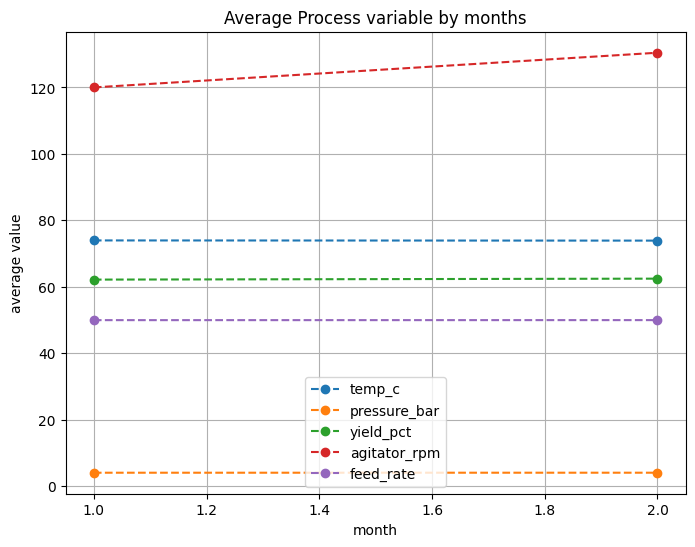

In [47]:
groupby_months = cleaned_data.groupby("month")[['temp_c', 'pressure_bar', 'yield_pct', 'agitator_rpm', 'feed_rate']].mean()
groupby_months.plot(
    linestyle='--',
    marker='o', 
    figsize=(8, 6)
)
plt.title("Average Process variable by months")
plt.ylabel("average value")
plt.grid()
plt.savefig("../docs/09_change_values_time")
plt.show()

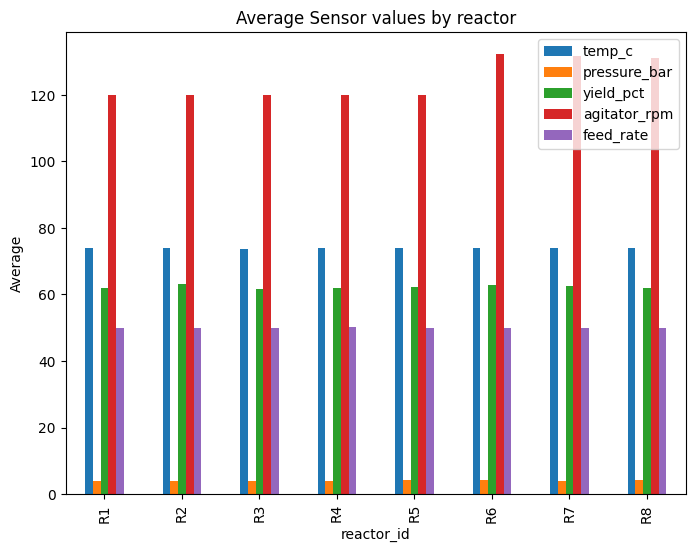

In [52]:
reactor_summary = cleaned_data.groupby('reactor_id')[['temp_c', 'pressure_bar', 'yield_pct', 'agitator_rpm', 'feed_rate']].mean()
reactor_summary.plot(
    kind='bar',
    figsize=(8, 6)
)
plt.title("Average Sensor values by reactor")
plt.ylabel("Average")
plt.savefig("../docs/average_values_per_reactor.png")
plt.show()

In [71]:
cleaned_data.isna().sum().to_csv("../docs/missing_values.csv")


In [ ]:
# group the data by batch and get the yield lower than zero for each batch 
groupby_batch = cleaned_data.groupby("batch_id")['yield_pct'].apply(lambda x: (x == 0).sum())
groupby_batch

batch_id
0          0
1          0
2          0
3          0
4          0
        ... 
11106      0
11107      0
11108      0
11109    180
11110      0
Name: yield_pct, Length: 11111, dtype: int64

In [65]:
filter_data = groupby_batch[groupby_batch > 0]
filter_data
filter_data.to_csv("../docs/filter_data_yield_zero.csv")